# FAO-56 crop coefficient ($K_c$) curve – maize, CCFC (Alta Verapaz)

- **Stage lengths:** FAO-56 Table 11, maize (grain), East Africa (alt.), April sowing.
- **$K_{c,ini}$:** FAO-56 Fig. 29 (wetting interval ~2.5 d, ET0 ~3–4 mm/d).
- **$K_{c,mid}$:** FAO-56 Eq. 62 with Open-Meteo stage means (u2 = 1.40 m/s, RHmin = 57 %, h = 2.5 m).
- **$K_{c,end}$ = 0.35:** cobs dried in the field (FAO-56 Table 12; no climate adjustment since the value is < 0.45). This fits the plants being left standing until cut-down.
- **After harvest:** the cobs are harvested at the end of the late stage (end Sep – early Oct), but the plants stay standing until they are cut down on **13 Oct 2026** (morning). Between harvest and cut-down, the dry standing plants are assumed to keep $K_c = K_{c,end}$ (constant). The curve stops on the cut-down day; 13 Oct is not included, since the plants were cut in the morning.

Outputs: a figure (`kc_curve_maize_CCFC.png`) and a daily table (`Kc_daily_maize_CCFC.csv`) with one row per day of year $J$.

## 1. Inputs – the only cell you need to edit

In [1]:
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SOWING   = date(2026, 4, 10)
L_INI, L_DEV, L_MID, L_LATE = 30, 50, 60, 40   # stage lengths [days], FAO-56 Table 11
CUT_DOWN = date(2026, 10, 13)                  # plants cut down (morning) -> last day with standing plants = 12 Oct

KC_INI = 0.85
KC_MID = 1.13
KC_END = 0.35                                  # grain dried in the field (Table 12)

OUTFIG = 'kc_curve_maize_CCFC.png'
OUTCSV = 'Kc_daily_maize_CCFC.csv'

## 2. Daily $K_c$ (FAO-56 Eq. 66) and the post-harvest phase

In [2]:
L_SEASON = L_INI + L_DEV + L_MID + L_LATE
HARVEST  = SOWING + timedelta(days=L_SEASON)            # end of the late stage
assert HARVEST <= CUT_DOWN, 'Cut-down date is before the end of the late stage - check the stage lengths.'
print(f'Sowing  : {SOWING:%d %b %Y} (J = {SOWING.timetuple().tm_yday})')
print(f'Harvest : {HARVEST:%d %b %Y} (J = {HARVEST.timetuple().tm_yday})  <- end of late stage')
print(f'Cut down: {CUT_DOWN:%d %b %Y} (J = {CUT_DOWN.timetuple().tm_yday})')


def kc_value(i, kc_ini, kc_mid, kc_end):
    '''Kc on day i after sowing: FAO-56 Eq. 66 (linear in dev and late stages), then constant Kc_end after harvest.'''
    if i < L_INI:
        return kc_ini
    if i < L_INI + L_DEV:
        return kc_ini + (i - L_INI) / L_DEV * (kc_mid - kc_ini)
    if i < L_INI + L_DEV + L_MID:
        return kc_mid
    if i < L_SEASON:
        return kc_mid + (i - (L_INI + L_DEV + L_MID)) / L_LATE * (kc_end - kc_mid)
    return kc_end                                          # harvested, plants still standing


def stage_name(i):
    for lim, name in [(L_INI, 'initial'), (L_INI + L_DEV, 'development'),
                      (L_INI + L_DEV + L_MID, 'mid-season'), (L_SEASON, 'late season')]:
        if i < lim:
            return name
    return 'post-harvest (standing)'


n_days = (CUT_DOWN - SOWING).days                          # sowing day ... day before cut-down
dates  = pd.date_range(SOWING, periods=n_days, freq='D')

kc = pd.DataFrame({
    'date': dates.date,
    'J': dates.dayofyear,
    'day_after_sowing': np.arange(n_days),
    'stage': [stage_name(i) for i in range(n_days)],
    'Kc': [round(kc_value(i, KC_INI, KC_MID, KC_END), 4) for i in range(n_days)],
})
kc.head()

Sowing  : 10 Apr 2026 (J = 100)
Harvest : 07 Oct 2026 (J = 280)  <- end of late stage
Cut down: 13 Oct 2026 (J = 286)


,date,J,day_after_sowing,stage,Kc
0,2026-04-10,100,0,initial,0.85
1,2026-04-11,101,1,initial,0.85
2,2026-04-12,102,2,initial,0.85
3,2026-04-13,103,3,initial,0.85
4,2026-04-14,104,4,initial,0.85


## 3. Save the daily table

One row per day, `J` = day of the year. To use it in another notebook:

```python
kc = pd.read_csv('Kc_daily_maize_CCFC.csv', index_col='J')
Kc_today = kc.loc[278, 'Kc']
```

In [3]:
kc.to_csv(OUTCSV, index=False)
print(f'Saved {OUTCSV}: {len(kc)} days, J = {kc.J.min()} to {kc.J.max()}')

Saved Kc_daily_maize_CCFC.csv: 186 days, J = 100 to 285


## 4. Figure

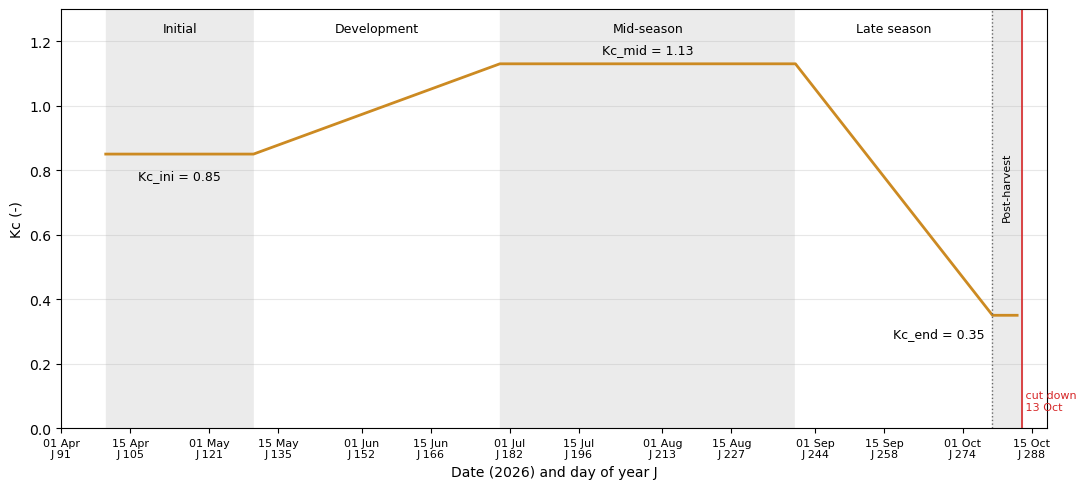

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))

# stage shading and labels
bounds = [0, L_INI, L_INI + L_DEV, L_INI + L_DEV + L_MID, L_SEASON, n_days]
names  = ['Initial', 'Development', 'Mid-season', 'Late season', 'Post-harvest']
for k, name in enumerate(names):
    start = SOWING + timedelta(days=bounds[k])
    end   = SOWING + timedelta(days=bounds[k + 1])
    ax.axvspan(start, end, color='0.92' if k % 2 == 0 else 'white', zorder=0)
    if name == 'Post-harvest':   # narrow band: vertical label
        ax.text(start + (end - start) / 2, 0.75, name, ha='center', va='center', rotation=90, fontsize=8)
    else:
        ax.text(start + (end - start) / 2, 1.22, name, ha='center', va='bottom', fontsize=9)

# Kc curves
ax.plot(kc['date'], kc['Kc'], color='#CC8A22', lw=2)

# harvest and cut-down
ax.axvline(HARVEST, color='0.4', lw=1, ls=':')
ax.axvline(CUT_DOWN, color='tab:red', lw=1.2)
ax.text(CUT_DOWN, 0.05, ' cut down\n 13 Oct', color='tab:red', fontsize=8, va='bottom')

# key values
ax.annotate(f'Kc_ini = {KC_INI}', (SOWING + timedelta(days=L_INI / 2), KC_INI),
            xytext=(0, -18), textcoords='offset points', ha='center', fontsize=9)
ax.annotate(f'Kc_end = {KC_END}', (HARVEST, KC_END),
            xytext=(-6, -16), textcoords='offset points', ha='right', fontsize=9)
ax.annotate(f'Kc_mid = {KC_MID}', (SOWING + timedelta(days=L_INI + L_DEV + L_MID / 2), KC_MID),
            xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9)

# x axis: date + day of year, ticks on the 1st and 15th of each month
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
ax.xaxis.set_major_formatter(plt.FuncFormatter(
    lambda x, _: f"{mdates.num2date(x):%d %b}\nJ {mdates.num2date(x).timetuple().tm_yday}"))
ax.tick_params(axis='x', labelsize=8)
ax.set_xlim(date(SOWING.year, SOWING.month, 1), CUT_DOWN + timedelta(days=5))
ax.set_ylim(0, 1.3)
ax.set_xlabel('Date (2026) and day of year J')
ax.set_ylabel('Kc (-)')
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
fig.savefig(OUTFIG, dpi=200)
plt.show()